# End-to-End Example: Single Article With Image

This notebook demonstrates the complete pipeline on one news article and one image path:

1. Define the article and image input.
2. Run the integrated pipeline (captioning + NER + sentiment + alert generation).
3. Inspect intermediate outputs and the final generated alert.

In [2]:
from pathlib import Path
import json
import matplotlib.pyplot as plt
from PIL import Image

from utils.pipeline import NewsAlertPipeline

c:\Users\lucia\anaconda3\envs\deep_new\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Step 1. Define Inputs

We provide a single article text and a local image path. The path logic is robust to whether the notebook is run from the project root or from the `src` folder.

In [3]:
NOTEBOOK_DIR = Path.cwd()
PROJECT_ROOT = NOTEBOOK_DIR if (
    NOTEBOOK_DIR / "data").exists() else NOTEBOOK_DIR.parent

article_text = (
    """U.S. President Donald Trump announced this Sunday that he is sending a negotiating team to Islamabad to hold a 
    second meeting with Iranian officials before the truce agreed with Tehran expires this Wednesday. The president 
    described the meeting as the last opportunity to accept peace and warned on social media that, if an agreement is 
    not signed, the country would be bombed in key infrastructure such as bridges and power plants. This escalation in 
    tension comes amid cross-threats over control of the Strait of Hormuz. Washington accuses Iran of attacking British 
    and French cargo ships in recent hours, while Tehran claims it has only intercepted oil tankers to pressure against 
    the U.S. blockade. Iran's army chief, Amir Hatami, responded to the warnings by saying his forces are ready for 
    confrontation and are keeping their finger on the trigger in case armed conflict resumes. The U.S. delegation is 
    scheduled to arrive in the Pakistani capital this Monday. Although Trump said Vice President JD Vance would not travel 
    for security reasons, several U.S. and Pakistani media outlets claim that Vance will lead the team together with mediator 
    Steve Witkoff and adviser Jared Kushner. Meanwhile, Iran's official Tasnim agency reported that Tehran will not attend 
    talks while Washington's maritime blockade remains in place, although the speaker of the Iranian parliament, Mohammad 
    Bagher Qalibaf, acknowledged that there has been some progress, even if a final agreement still appears distant. The 
    nuclear program remains the second major obstacle in the negotiations. The Trump administration is demanding full 
    dismantlement and the handover of all enriched uranium, while the Islamic Republic insists on maintaining its 
    enrichment plan for civilian use. International analysts warn that the fragility of the open fronts in Hormuz, the 
    nuclear sphere, and the offensive in Lebanon could cause the diplomatic process to fail at any moment."""
)

image_path = PROJECT_ROOT / "data" / "expert_images" / "trump_iran_reunion.png"

print(f"Project root: {PROJECT_ROOT}")
print(f"Image path: {image_path}")

Project root: c:\Users\lucia\OneDrive - Universidad Pontificia Comillas\Documentos\2025-2026\2º Semestre\DEEP LEARNING\final-project-nlp-dl-gru
Image path: c:\Users\lucia\OneDrive - Universidad Pontificia Comillas\Documentos\2025-2026\2º Semestre\DEEP LEARNING\final-project-nlp-dl-gru\data\expert_images\trump_iran_reunion.png


Before running the model, we check that the file exists and display it.

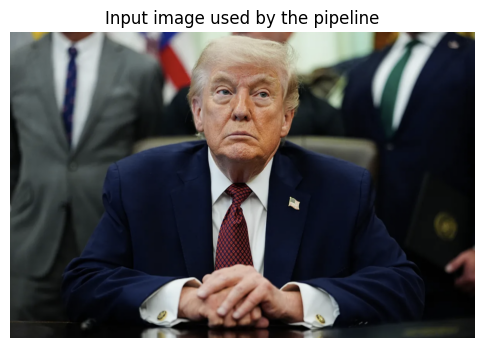

In [4]:
if not image_path.exists():
    raise FileNotFoundError(f"Image file not found: {image_path}")

img = Image.open(image_path)
plt.figure(figsize=(6, 4))
plt.imshow(img)
plt.axis("off")
plt.title("Input image used by the pipeline")
plt.show()

## Step 2. Run the Complete Pipeline

This call runs the full process for a single input: image captioning, named entity recognition (NER), sentiment analysis (SA), and final alert generation.

In [5]:
pipeline = NewsAlertPipeline()

result = pipeline.run(
    article_text=article_text,
    image_path=str(image_path),
)

Loading weights: 100%|██████████| 473/473 [00:00<00:00, 1308.35it/s]
BlipForConditionalGeneration LOAD REPORT from: Salesforce/blip-image-captioning-base
Key                                       | Status     |  | 
------------------------------------------+------------+--+-
text_decoder.bert.embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
W0423 16:46:32.336000 23324 site-packages\torch\utils\flop_counter.py:29] triton not found; flop counting will not work for triton kernels
Loading weights: 100%|██████████| 339/339 [00:04<00:00, 69.52it/s] 
The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


## Step 3. Inspect Intermediate Outputs

The pipeline returns the generated image caption, normalized NER output, and sentiment prediction used as inputs for the alert model.

In [5]:
print("Generated image caption:")
print(result["image_caption"])

print("\nNormalized NER output:")
print(result["ner_normalized"][:60])

print("\nSentiment prediction:")
print(result["sentiment"])

Generated image caption:
president donald trump sits at a desk in the oval room of the white house

Normalized NER output:
U.S. (LOCATION), Donald Trump (PERSON), Islamabad (LOCATION)

Sentiment prediction:
negative


## Step 4. Show the Final Alert

Finally, we print the alert JSON produced by the fine-tuned alert model and a compact summary line for quick interpretation.

In [6]:
final_alert = result["final_alert"]
print(json.dumps(final_alert, indent=2, ensure_ascii=False))

print("\nSummary:")
print(
    f"is_alert={final_alert.get('is_alert')} | "
    f"level={final_alert.get('alert_level')} | "
    f"category={final_alert.get('category')}"
)

{
  "is_alert": true,
  "alert_level": "critical",
  "category": "geopolitical",
  "reason": "Tension between U.S. and Iran escalates with potential military action and failed negotiations.",
  "source": "fine_tuned_alert_model"
}

Summary:
is_alert=True | level=critical | category=geopolitical
